In [2]:
import pandas as pd
import geopandas as gpd
import os
import pandas as pd
import numpy as np
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from shapely.geometry import Point, Polygon, mapping
from fiona import collection
import matplotlib.pyplot as plt
import alphashape
import netCDF4 as nc
import xarray as xr
import regionmask
import scipy
from scipy import signal

In [3]:
def to_ts(file, dim, var, var_name, timeslice=None, detrend=False):
    '''
    extract a time series dataframe from netCDF file

    Parameters:
    - file (str): path to .nc data file
    - dim (list): input spatial dimension names (e.g., ['lat', 'lon'])
    - var (str): variable name in .nc
    - var_name (str): name for output time series variable

    Returns:
    - pd.DataFrame: DataFrame with time as index and column for the variable
    '''
    
    ds = xr.open_dataset(file)
    
    if timeslice is not None:
        ds = ds.sel(time=slice(timeslice[0], timeslice[1]))

    ds[var] = ds[var].astype(np.float64)
    ds_avg = ds.mean(dim=dim)
        
    if detrend:
        for j in range(12):
            ds_avg[var][j::12] = signal.detrend(ds_avg[var][j::12], axis=0)
    
    ts = ds_avg[var].to_pandas().rename(var_name)
    
    time = list(ds_avg['time'].values)
    var_values = list(ts.values)
    
    return pd.DataFrame({var_name: var_values}, index=time)

In [4]:
def to_ts2(ds, dim, var, var_name, timeslice=None, detrend=False):
    '''
    extract a time series dataframe from netCDF file

    Parameters:
    - ds (str): xarray object
    - dim (list): input spatial dimension names (e.g., ['lat', 'lon'])
    - var (str): variable name in .nc
    - var_name (str): name for output time series variable

    Returns:
    - pd.DataFrame: DataFrame with time as index and column for the variable
    '''
    
    if timeslice is not None:
        ds = ds.sel(time=slice(timeslice[0], timeslice[1]))

    ds[var] = ds[var].astype(np.float64)
    ds_avg = ds.mean(dim=dim)
    ds_avg = ds_avg.squeeze()
    
    if detrend:
        for j in range(12):
            ds_avg[var][j::12] = signal.detrend(ds_avg[var][j::12], axis=0)

    ts = ds_avg[var].to_pandas().rename(var_name)

    time = list(ds_avg['time'].values)
    var_values = list(ts.values)

    return pd.DataFrame({var_name: var_values}, index=time)

In [102]:
path = '/Users/ernest/Research/thesis/_paper_/'

### AMOC

In [6]:
sst_era5 = xr.open_dataset(path + 'data/AMOC/ERA5-monthly-global-SST.nc')
sst_hadcrut5 = xr.open_dataset(path + 'data/AMOC/HadCRUT5/HadCRUT.5.0.2.0.analysis.anomalies.ensemble_mean.nc')
sst_hadsst4 = xr.open_dataset(path + 'data/AMOC/HadSST4/HadSST.4.0.1.0_median.nc')
sst_cobe = xr.open_dataset(path + 'data/AMOC/COBE-SST2/sst.mon.mean.nc')
sst_ersst = xr.open_dataset(path + 'data/AMOC/noaa.ersst.v5/sst.mnmean.nc')

In [7]:
spg = gpd.read_file(path + 'data/shapefiles/spg_outline.shp')

In [20]:
spg_mask = regionmask.mask_3D_geopandas(spg, sst_era5.longitude, sst_era5.latitude)
spg_era5 = sst_era5.where(spg_mask)

spg_mask = regionmask.mask_3D_geopandas(spg, sst_hadcrut5.longitude, sst_hadcrut5.latitude)
spg_hadcrut5 = sst_hadcrut5.where(spg_mask)

spg_mask = regionmask.mask_3D_geopandas(spg, sst_hadsst4.longitude, sst_hadsst4.latitude)
spg_hadsst4 = sst_hadsst4.where(spg_mask)

spg_mask = regionmask.mask_3D_geopandas(spg, sst_cobe.lon, sst_cobe.lat)
spg_cobe = sst_cobe.where(spg_mask)

spg_mask = regionmask.mask_3D_geopandas(spg, sst_ersst.lon, sst_ersst.lat)
spg_ersst = sst_ersst.where(spg_mask)

In [21]:
ts_era5 = to_ts2(sst_era5, ['latitude','longitude'], 'sst', 'sst_glob',
             timeslice=('1982-01-01', '2022-12-31'), detrend=True)
ts_spg_era5 = to_ts2(spg_era5, ['latitude','longitude'], 'sst', 'sst_spg',
             timeslice=('1982-01-01', '2022-12-31'), detrend=True)

ts_hadcrut5 = to_ts2(sst_hadcrut5, ['latitude','longitude'], 'tas_mean', 'sst_glob',
             timeslice=('1982-01-01', '2022-12-31'), detrend=True)
ts_spg_hadcrut5 = to_ts2(spg_hadcrut5, ['latitude','longitude'], 'tas_mean', 'sst_spg',
             timeslice=('1982-01-01', '2022-12-31'), detrend=True)

ts_hadsst4 = to_ts2(sst_hadsst4, ['latitude','longitude'], 'tos', 'sst_glob',
             timeslice=('1982-01-01', '2022-12-31'), detrend=True)
ts_spg_hadsst4 = to_ts2(spg_hadsst4, ['latitude','longitude'], 'tos', 'sst_spg',
             timeslice=('1982-01-01', '2022-12-31'), detrend=True)

ts_cobe = to_ts2(sst_cobe, ['lat','lon'], 'sst', 'sst_glob',
             timeslice=('1982-01-01', '2022-12-31'), detrend=True)
ts_spg_cobe = to_ts2(spg_cobe, ['lat','lon'], 'sst', 'sst_spg',
             timeslice=('1982-01-01', '2022-12-31'), detrend=True)

ts_ersst = to_ts2(sst_ersst, ['lat','lon'], 'sst', 'sst_glob',
             timeslice=('1982-01-01', '2022-12-31'), detrend=True)
ts_spg_ersst = to_ts2(spg_ersst, ['lat','lon'], 'sst', 'sst_spg',
             timeslice=('1982-01-01', '2022-12-31'), detrend=True)

In [22]:
AMOC_era5 = pd.concat([ts_spg_era5, ts_era5], axis=1)
AMOC_era5['AMOC_era5']= AMOC_era5['sst_spg'] - AMOC_era5['sst_glob']

AMOC_hadcrut5 = pd.concat([ts_spg_hadcrut5, ts_hadcrut5], axis=1)
AMOC_hadcrut5['AMOC_hadcrut5']= AMOC_hadcrut5['sst_spg'] - AMOC_hadcrut5['sst_glob']

AMOC_hadsst4 = pd.concat([ts_spg_hadsst4, ts_hadsst4], axis=1)
AMOC_hadsst4['AMOC_hadsst4']= AMOC_hadsst4['sst_spg'] - AMOC_hadsst4['sst_glob']

AMOC_cobe = pd.concat([ts_spg_cobe, ts_cobe], axis=1)
AMOC_cobe['AMOC_cobe']= AMOC_cobe['sst_spg'] - AMOC_cobe['sst_glob']

AMOC_ersst = pd.concat([ts_spg_ersst, ts_ersst], axis=1)
AMOC_ersst['AMOC_ersst']= AMOC_ersst['sst_spg'] - AMOC_ersst['sst_glob']

In [23]:
AMOC_hadcrut5 = AMOC_hadcrut5.resample('M').mean()
AMOC_hadcrut5.index = AMOC_hadcrut5.index + pd.offsets.MonthBegin(-1)

AMOC_hadsst4 = AMOC_hadsst4.resample('M').mean()
AMOC_hadsst4.index = AMOC_hadsst4.index + pd.offsets.MonthBegin(-1)
AMOC_hadsst4

,sst_spg,sst_glob,AMOC_hadsst4
1982-01-01,0.499696,0.020140,0.479555
1982-02-01,0.138612,-0.056504,0.195116
1982-03-01,0.220777,-0.070930,0.291707
1982-04-01,-0.069163,-0.001018,-0.068145
1982-05-01,-0.253298,0.021271,-0.274569
...,...,...,...
2022-08-01,-0.033149,-0.033875,0.000726
2022-09-01,0.649152,-0.023753,0.672905
2022-10-01,0.503214,-0.000027,0.503241
2022-11-01,-0.191246,0.017786,-0.209032


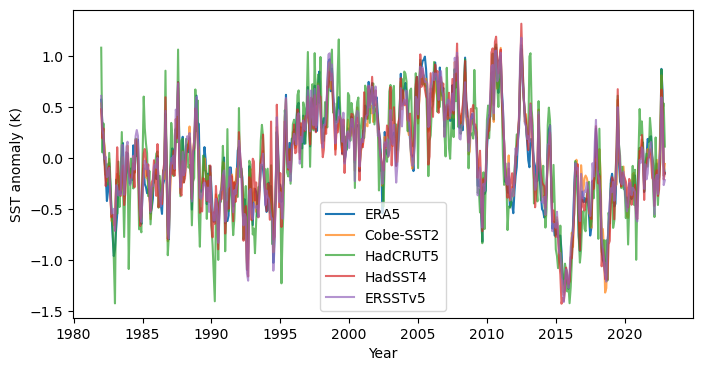

In [105]:
plt.figure(figsize=(8, 4))

plt.plot(AMOC_era5['AMOC_era5'], label='ERA5')
plt.plot(AMOC_cobe['AMOC_cobe'], label='Cobe-SST2', alpha=.7)
plt.plot(AMOC_hadcrut5['AMOC_hadcrut5'], label='HadCRUT5', alpha=.7)
plt.plot(AMOC_hadsst4['AMOC_hadsst4'], label='HadSST4', alpha=.7)
plt.plot(AMOC_ersst['AMOC_ersst'], label = 'ERSSTv5', alpha=.7)
plt.xlabel('Year')
plt.ylabel('SST anomaly (K)')
plt.legend()
plt.savefig(path + 'figures/S-Figure_1.png', dpi=300, bbox_inches='tight', transparent=True);

### CLLJ

In [25]:
# units: m/s
CLLJ = to_ts(path + 'data/CLLJ/cdo-fldmean/CLLJ_u-wind_aggregated.nc', ['lat','lon'], 'u', 'CLLJ', 
             timeslice=('1982-01-01', '2022-12-31'), detrend=True)
CLLJ = -CLLJ

### AR precipitation

In [26]:
# ERA5 (m of water equivalent per day)
# tp [mm] = tp [m/day]⋅1000⋅N
ERA5_prec = to_ts(path + 'data/AR/prec/ERA5_south.nc', ['latitude','longitude'], 'tp', 'SAR_prec', 
                      timeslice=('1982-01-01', '2022-12-31'), detrend=True)

### AR NDVI

In [106]:
NDVI_bw = to_ts(path + 'data/AR/ndvi/south.nc4',
      ['lat','lon'], 'ndvi', 'NDVI', timeslice=('1982-01-01', '2022-12-31'), detrend=True)

# resample + reindex
NDVI = NDVI_bw.resample('M').mean()
NDVI.index = NDVI.index + pd.offsets.MonthBegin(-1)

### mask

In [28]:
# SAR dry season (MJJAS)
pattern = [1,1,1,1,0,0,0,0,0,1,1,1] * 41

## merge + re-index

### ERA5 (1982-2022)

In [29]:
ERA5 = pd.concat([AMOC_era5['AMOC_era5'], AMOC_hadcrut5['AMOC_hadcrut5'], 
                  AMOC_hadsst4['AMOC_hadsst4'], AMOC_cobe['AMOC_cobe'], 
                  AMOC_ersst['AMOC_ersst'], CLLJ, ERA5_prec, NDVI], axis=1)

ERA5 = ERA5.reset_index().rename(columns={'index': 'time'})
ERA5['Southern AR dry season'] = pattern
ERA5

,time,AMOC_era5,AMOC_hadcrut5,AMOC_hadsst4,AMOC_cobe,AMOC_ersst,CLLJ,SAR_prec,NDVI,Southern AR dry season
0,1982-01-01,0.573397,1.084507,0.479555,0.536978,0.611327,-0.365887,0.000504,-168.179598,1
1,1982-02-01,0.336767,0.056201,0.195116,0.295782,0.280656,0.039025,0.000249,-231.937396,1
2,1982-03-01,0.074182,0.341188,0.291707,0.196003,0.228871,0.657247,-0.000834,-115.396364,1
3,1982-04-01,-0.029423,-0.014307,-0.068145,0.121964,-0.005972,0.104014,0.000448,-93.576626,1
4,1982-05-01,-0.160463,-0.167537,-0.274569,-0.039897,0.013368,-1.868915,-0.000363,-199.433349,0
...,...,...,...,...,...,...,...,...,...,...
487,2022-08-01,0.155575,-0.045180,0.000726,0.265877,0.072585,0.173786,0.000286,-136.678083,0
488,2022-09-01,0.876525,0.870340,0.672905,0.814319,0.597346,-0.997812,-0.000310,-335.963465,0
489,2022-10-01,0.660696,0.484523,0.503241,0.506393,0.422334,0.377371,0.000110,-185.535830,1
490,2022-11-01,-0.075736,0.536517,-0.209032,-0.174987,-0.264646,-0.219247,-0.002352,244.348158,1


In [553]:
ERA5.to_csv(path + 'data/ERA5_1982-2022.csv')

## std dev to total units

In [30]:
# AMOC index is given as SST anomaly in K. Caesar et al. have derived slope of 3.8 K/Sv for conversion
# need to only consider FMAMJJ part of the time series

AMOC_era5['AMOC_era5']

1982-01-01    0.573397
1982-02-01    0.336767
1982-03-01    0.074182
1982-04-01   -0.029423
1982-05-01   -0.160463
                ...   
2022-08-01    0.155575
2022-09-01    0.876525
2022-10-01    0.660696
2022-11-01   -0.075736
2022-12-01   -0.152207
Name: AMOC_era5, Length: 492, dtype: float64

In [32]:
filtered_AMOC_era5 = AMOC_era5['AMOC_era5'][AMOC_era5['AMOC_era5'].index.month.isin([2, 3, 4, 5, 6, 7])]

In [38]:
stdev_index = np.std(filtered_AMOC_era5) # units K, SST Anomaly
stdev_index

0.4574129473729387

In [39]:
stdev_AMOC = stdev_index * 3.8 # units Sv
stdev_AMOC

1.738169200017167

In [77]:
# ERA5 (m of water equivalent per day)
# tp [mm] = tp [m/day]⋅1000⋅N
ERA5_prec = to_ts(path + 'data/AR/prec/ERA5_south.nc', ['latitude','longitude'], 'tp', 'SAR_prec', 
                      timeslice=('1982-01-01', '2022-12-31'), detrend=False)
days_in_month = [31, 28, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31]*41

# Convert to mm/month by multiplying by 1000 and the days in the respective month
ERA5_prec_mm = ERA5_prec['SAR_prec'] * 1000 * days_in_month
ERA5_prec_mm

1982-01-01    313.867312
1982-02-01    271.137014
1982-03-01    249.437866
1982-04-01    224.185585
1982-05-01    115.551303
                 ...    
2022-08-01     45.378827
2022-09-01     62.782517
2022-10-01    166.337287
2022-11-01    153.967974
2022-12-01    273.118731
Name: SAR_prec, Length: 492, dtype: float64

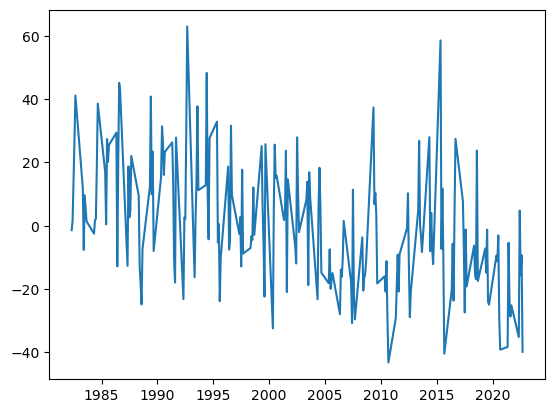

In [78]:
filtered_PREC_era5 = ERA5_prec_mm[ERA5_prec_mm.index.month.isin([5, 6, 7, 8, 9])]

climatology = filtered_PREC_era5.groupby(filtered_PREC_era5.index.month).mean()

# Subtract climatology to get monthly anomalies
monthly_anomalies = filtered_PREC_era5 - filtered_PREC_era5.index.map(lambda x: climatology[x.month])

plt.plot(monthly_anomalies);

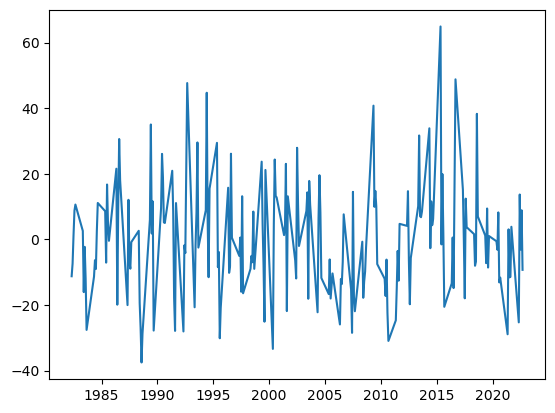

In [81]:
ERA5_prec = to_ts(path + 'data/AR/prec/ERA5_south.nc', ['latitude','longitude'], 'tp', 'SAR_prec', 
                      timeslice=('1982-01-01', '2022-12-31'), detrend=True)

days_in_month = [31, 28, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31]*41

# Convert to mm/month by multiplying by 1000 and the days in the respective month
ERA5_prec_mm = ERA5_prec['SAR_prec'] * 1000 * days_in_month
ERA5_prec_mm

filtered_PREC_era5 = ERA5_prec_mm[ERA5_prec_mm.index.month.isin([5, 6, 7, 8, 9])]

plt.plot(filtered_PREC_era5);

In [85]:
# no detrending, but removal of climatology

stdev_PREC = np.std(monthly_anomalies)
stdev_PREC

20.114151024605448

In [87]:
# detrending

stdev_PREC = np.std(filtered_PREC_era5)
stdev_PREC

17.11629954721246

In [90]:
# mm/month per Sv weakening:
CE = -0.31

stdev_PREC / stdev_AMOC * CE

-3.052667634188581